In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/Rabii_2026-10-18/measurements_23:27.csv", skipinitialspace=True)
df

,Size,Type,Time
0,100,Sequential,0.000006
1,100,Parallel,0.007326
2,100,Built-in,0.000007
3,100,Sequential,0.000007
4,100,Parallel,0.009111
...,...,...,...
70,1000000,Parallel,0.152741
71,1000000,Built-in,0.136892
72,1000000,Sequential,0.130596
73,1000000,Parallel,0.163294


In [8]:
df.groupby(["Size", "Type"])["Time"].mean().unstack()

Type,Built-in,Parallel,Sequential
Size,,,
100,0.000006,0.008335,0.000007
1000,0.000075,0.033333,0.000074
10000,0.000913,0.056467,0.001004
100000,0.011987,0.079727,0.011437
1000000,0.136278,0.161607,0.133891


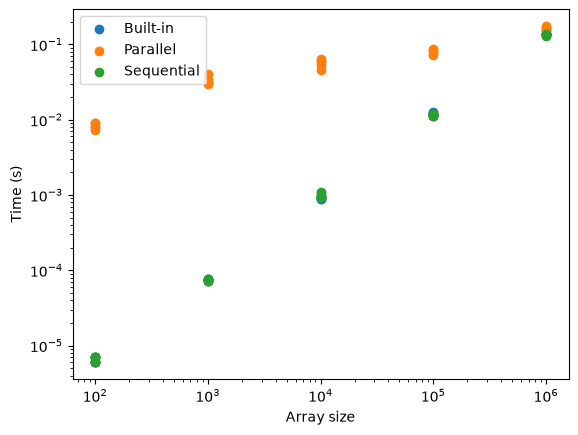

In [9]:
for t, g in df.groupby("Type"):
    plt.scatter(g["Size"], g["Time"], label=t)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

I can't see the Built-in points, so let's give each algorithm its own shape.

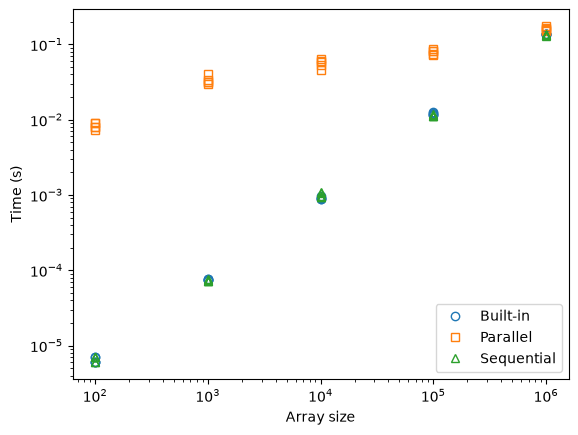

In [10]:
markers = {"Built-in": "o", "Parallel": "s", "Sequential": "^"}
for t, g in df.groupby("Type"):
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", label=t)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

For better visibility on the plot, let's add lines connecting the points for each algorithm. This will help to visualize the trend of each algorithm's performance.

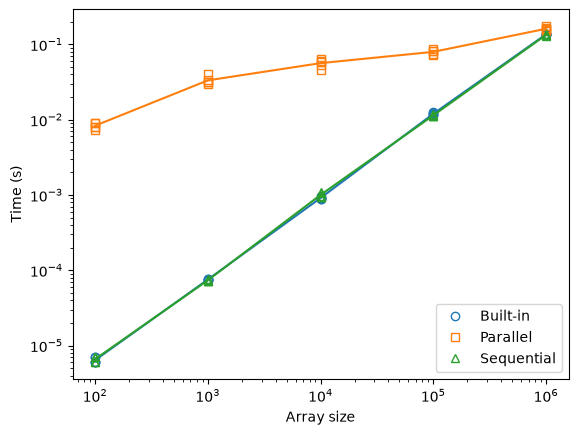

In [11]:
for i, (t, g) in enumerate(df.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

It seems that the parallel algorithm is consistently slower than the sequential one across all input sizes. This is contrary to what was observed in `journal.org`, where the parallel algorithm outperformed the sequential one for larger input sizes (above ~400k).

maybe this is due to laptop hardware/software differences. but we can also notice that the two trends are close to each other at around 1M, which is the largest input size we tested. It would be interesting to see if the parallel algorithm starts to outperform the sequential one at even larger input sizes.

Let's make the same tests but with larger input sizes, but not adding too many sizes to not overload the laptop.

adding sizes 2M, 5M, 10M.

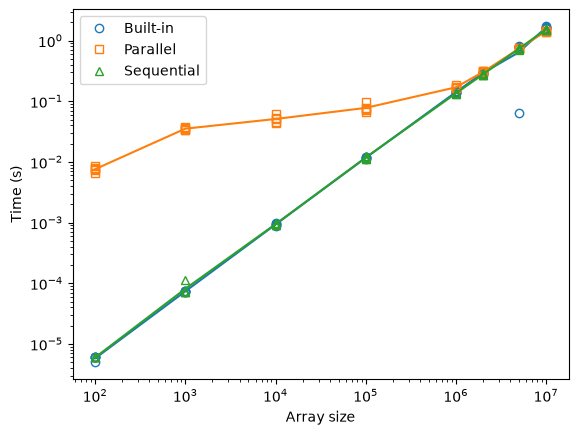

In [12]:
df2 = pd.read_csv("data/Rabii_2026-10-19/measurements_00:02.csv", skipinitialspace=True)
for i, (t, g) in enumerate(df2.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

Need to investigate that aberrant point.

In [13]:
df2[df2["Size"] == 5000000]

,Size,Type,Time
90,5000000,Sequential,0.752178
91,5000000,Parallel,0.741670
92,5000000,Built-in,0.814779
93,5000000,Sequential,0.753225
94,5000000,Parallel,0.729854
95,5000000,Built-in,0.781414
96,5000000,Sequential,0.734353
97,5000000,Parallel,0.743709
98,5000000,Built-in,0.775089
99,5000000,Sequential,0.707608


Row 104 seems odd: Built-in took 0.063846 s, while the other four Built-in runs at 5M took about 0.78 s (12× slower). Maybe some error on the machine provoked it, so let's redo the same run.

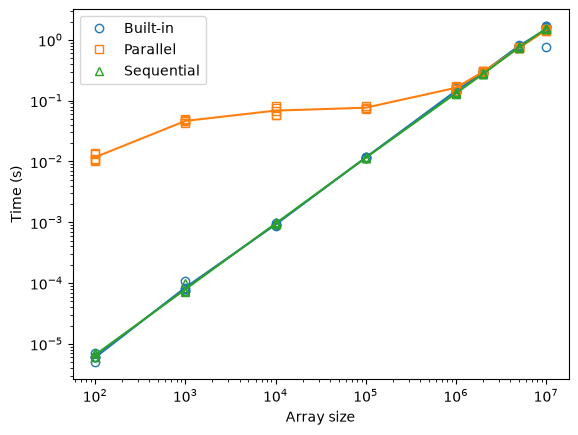

In [14]:
df3 = pd.read_csv("data/Rabii_2026-10-19/measurements_00:09.csv", skipinitialspace=True)
for i, (t, g) in enumerate(df3.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

In [15]:
df3[df3["Size"] == 10000000]

,Size,Type,Time
104,10000000,Sequential,1.513047
105,10000000,Parallel,1.481359
106,10000000,Built-in,1.647411
107,10000000,Sequential,1.517740
108,10000000,Parallel,1.436421
109,10000000,Built-in,1.658105
110,10000000,Sequential,1.536342
111,10000000,Parallel,1.413193
112,10000000,Built-in,0.774689
113,10000000,Sequential,1.529446


we've got again an aberrant point at 10M, but not as bad as before. 

This can be signs that this experiment is hard to reproduce.